In [1]:
import os
os.environ['CUDA_VISIBLE_DEVICES'] = '0'

In [2]:
import jax

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr

In [4]:
import matplotlib.pyplot as plt

In [5]:
from daops.data.vortex import *
from daops.utils.serial import *
from daops.modules.gnot import GNOTConfig
from daops.data.data_utils import *

# SDF Data

In [6]:
dataset_cyl = VortexWindowDataset("./data/cylinder_train.h5", 6, 2, 50, 75, indices=(0, 18))
dataset_tri = VortexWindowDataset("./data/triangle_train.h5", 6, 2, 50, 75, indices=(0, 18))
dataset_box = VortexWindowDataset("./data/box_train.h5", 6, 2, 50, 75, indices=(0, 18))
dataset_diamond = VortexWindowDataset("./data/diamond_train.h5", 6, 2, 50, 75, indices=(0, 18))

sdf_dataset_cyl = VortexSDFDataset("./data/cylinder_train.h5", 2, 50, 75, indices=(0, 18))
sdf_dataset_tri = VortexSDFDataset("./data/triangle_train.h5", 2, 50, 75, indices=(0, 18))
sdf_dataset_box = VortexSDFDataset("./data/box_train.h5", 2, 50, 75, indices=(0, 18))
sdf_dataset_diamond = VortexSDFDataset("./data/diamond_train.h5", 2, 50, 75, indices=(0, 18))

In [7]:
task_sim_dataset = VortexRandomSubsampledDataset("./data/diamond_train.h5", 2, 6, 50, 75, indices=(0, 18),
                                                        paramed=False, subsample_rate=0.1)
dataloader_sim = DataLoader(task_sim_dataset, 2, True, collate_fn=jax_padding_collate)


In [8]:
dataset_tri[0]['u'].shape

(14580, 10)

In [9]:
task_sim_dataset[0].keys()

dict_keys(['domain', 'X', 'u', 'functions'])

In [10]:
dataset = dataset_diamond

In [11]:
dataloader = DataLoader(dataset, 6, True, collate_fn=jax_padding_collate)

In [31]:
make = partial(eqx.nn.make_with_state(GeoGNOT), fnames_return_geo=None)

In [32]:
model_task_shape = load_model("experiments/GeoGNOT/DOUBLE_META/3GEO_1SIM(tri)_FULLGRID_T=75_ADAMw(SGD1e-4)_K=6/ADAMW1E-4_N=10_SUB005_DIAMOND_DOUBLE_TRAINED_GAMMA=0.5_NMSE/checkpoint/2025-11-16_13-14-07/model_epoch_200.eqx", make)[0]
model_task_sim = load_model("experiments/GeoGNOT/DOUBLE_META/3GEO_1SIM(tri)_FULLGRID_T=75_ADAMw(SGD1e-4)_K=6/ADAMW1E-4_N=10_SUB005_DIAMOND_DOUBLE_TRAINED_GAMMA=0.5_NMSE/checkpoint/2025-11-16_13-14-07/model_epoch_200.eqx", make)[0]
# model_task_sim = load_model("/home/nhosse5/Documents/DA_operators/experiments/GeoGNOT/META_REPTILE/META_SHAPE_RANDOM_TASK_FixedDecay_ADAMw+JoinLinearExp(SGD1e-4)_K=5/CylinderSimulationTrainedGAMMA=0.5_T=75_NMSE/model.eqx", eqx.nn.make_with_state(GeoGNOT))[0]
# model_task_sim = None

In [33]:
import jax.tree_util as jtu

In [34]:
def is_function(path, function_name):
    for p in path:
        if isinstance(p, jtu.DictKey):
            if p.key==function_name:
                return True
    return False

def all_function(tree, function_name):
    leaves = jtu.tree_leaves_with_path(tree)
    bluffs = []
    for p, l in leaves:
        if is_function(p, function_name):
            bluffs.append(l)
    return bluffs       

In [35]:
data_cyl = sdf_dataset_cyl[0]
data_box = sdf_dataset_box[9]
data_tri = sdf_dataset_tri[7]
data_diamond = sdf_dataset_diamond[0]

## SDF

In [36]:
model = model_task_sim

In [37]:
data = sdf_dataset_diamond[1]
dataset = dataset_diamond
data = dataset[0]

In [38]:
model_task_sim.gnot.coord_transform

Standardization(min=f32[2], max=f32[2])

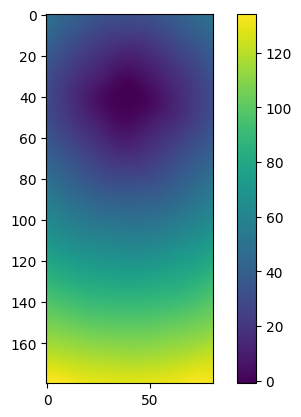

In [39]:
data = sdf_dataset_diamond[0]
_, geo = model(data['X'], data['functions'])
plt.imshow(geo.reshape(dataset.X.shape[0], dataset.X.shape[1]))
plt.colorbar()

In [40]:
jnp.mean((data['aux']['sdf'] - geo) ** 2)

Array(0.66265017, dtype=float32)

In [41]:
jnp.mean(jnp.linalg.norm(data['aux']['sdf'] - geo, axis=0) ** 2 / jnp.linalg.norm(data['aux']['sdf'], axis=0) **2)

Array(0.00015099, dtype=float32)

In [42]:
np.min(geo)

Array(-0.92673874, dtype=float32)

# Sim 

In [43]:
dataset_diamond = VortexWindowDataset("./data/diamond_train.h5", 6, 2, 50, 75, indices=(0, 18))

In [44]:
len(dataset_diamond)

144

In [45]:
model = model_task_sim
dataset = dataset_diamond

In [46]:
i = 5
data = dataset_diamond[i * 8]
pred, geo = model(data['X'], data['functions'])
label = unflatten(data['u'], dataset.X.shape[0], dataset.X.shape[1], 5)
pred = unflatten(pred, dataset.X.shape[0], dataset.X.shape[1], 5)
geo = geo.reshape(dataset.X.shape[0], dataset.X.shape[1])

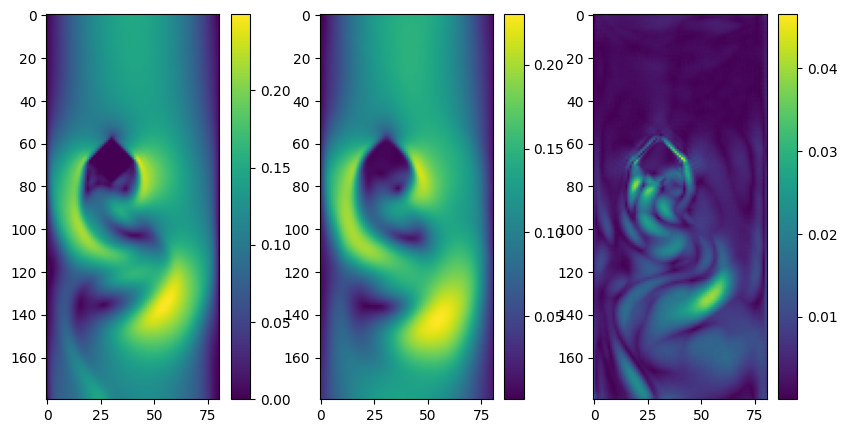

In [29]:
t_index = 7

plt.subplots(1, 3, figsize=(10, 5))
plt.subplot(1, 3, 1)
plt.imshow(np.linalg.norm(label[t_index], axis=0))
plt.colorbar()
plt.subplot(1, 3, 2)
plt.imshow(np.linalg.norm(pred[t_index], axis=0))
plt.colorbar()
plt.subplot(1, 3, 3)
plt.imshow(jnp.abs(label[t_index] - pred[t_index]).mean(axis=0))
plt.colorbar()  
plt.show()

In [55]:
pred.shape

(5, 2, 180, 81)

In [56]:
np.mean((pred - label) ** 2)

Array(9.593356e-05, dtype=float32)

In [57]:
label.shape

(5, 2, 180, 81)

In [71]:
np.mean(np.linalg.norm(pred - label, axis=(2, 3)) ** 2 / np.linalg.norm(label, axis=(2, 3)) **2)

np.float32(0.50561416)

In [26]:
data_cyl = dataset_box[0]
# _ = data_cyl['functions'].pop('bluff_body')
print(data_cyl['functions'].keys())
pred, geo = model_cyl(data_cyl['X'], data_cyl['functions'])
predd = unflatten(pred, dataset_cyl.X.shape[0], dataset_cyl.X.shape[1], 5)
geo = geo.reshape(dataset_cyl.X.shape[0], dataset_cyl.X.shape[1])

dict_keys(['bluff_body', 'velocity'])


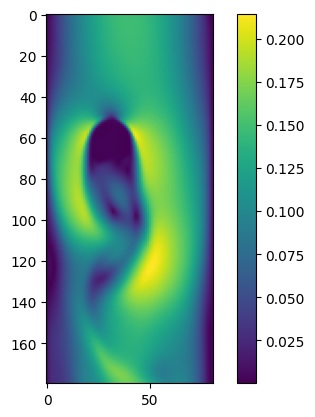

In [27]:
plt.imshow(np.linalg.norm(predd[0, :, :], axis=0))
plt.colorbar()

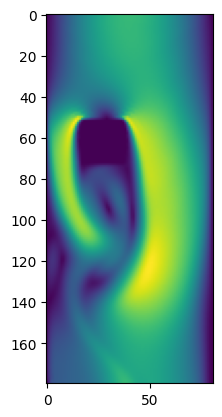

In [29]:
plt.imshow(np.linalg.norm(unflatten(data_cyl['u'], dataset_cyl.X.shape[0], dataset_cyl.X.shape[1], 5)[0], axis=0))

### Box SDF 

In [30]:
data_cyl = dataset_box[0]
# _ = data_cyl['functions'].pop('bluff_body')
print(data_cyl['functions'].keys())
pred, geo = model_boxsdf(data_cyl['X'], data_cyl['functions'])
predd = unflatten(pred, dataset_cyl.X.shape[0], dataset_cyl.X.shape[1], 5)
geo = geo.reshape(dataset_cyl.X.shape[0], dataset_cyl.X.shape[1])

dict_keys(['bluff_body', 'velocity'])


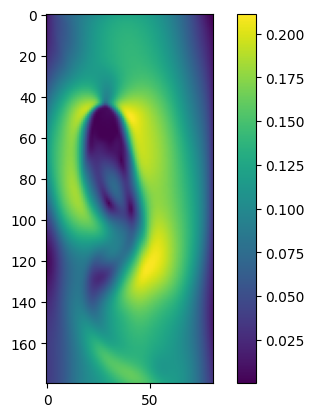

In [31]:
plt.imshow(np.linalg.norm(predd[0, :, :], axis=0))
plt.colorbar()

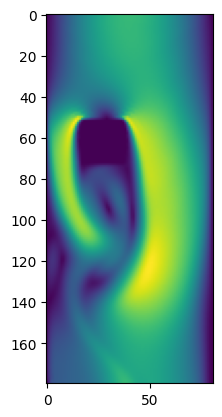

In [32]:
plt.imshow(np.linalg.norm(unflatten(data_cyl['u'], dataset_cyl.X.shape[0], dataset_cyl.X.shape[1], 5)[0], axis=0))

### Box Few

In [39]:
data_cyl = dataset_box[-1]
# _ = data_cyl['functions'].pop('bluff_body')
print(data_cyl['functions'].keys())
pred, geo = model_boxfew(data_cyl['X'], data_cyl['functions'])
predd = unflatten(pred, dataset_cyl.X.shape[0], dataset_cyl.X.shape[1], 5)
geo = geo.reshape(dataset_cyl.X.shape[0], dataset_cyl.X.shape[1])

dict_keys(['bluff_body', 'velocity'])


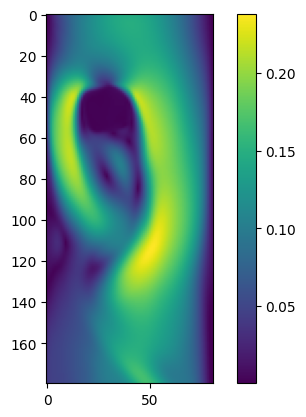

In [40]:
plt.imshow(np.linalg.norm(predd[0, :, :], axis=0))
plt.colorbar()

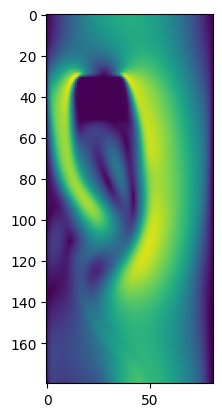

In [41]:
plt.imshow(np.linalg.norm(unflatten(data_cyl['u'], dataset_cyl.X.shape[0], dataset_cyl.X.shape[1], 5)[0], axis=0))

In [37]:
data_cyl = dataset_cyl[0]
# _ = data_cyl['functions'].pop('bluff_body')
print(data_cyl['functions'].keys())
pred, geo = model_cyl(data_cyl['X'], data_cyl['functions'])
predd = unflatten(pred, dataset_cyl.X.shape[0], dataset_cyl.X.shape[1], 5)
geo = geo.reshape(dataset_cyl.X.shape[0], dataset_cyl.X.shape[1])

dict_keys(['bluff_body', 'velocity'])


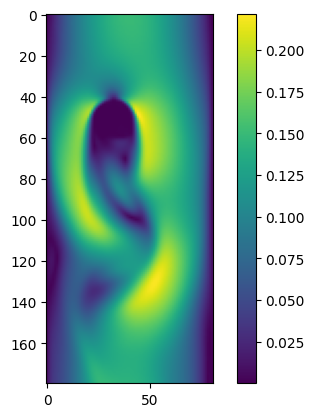

In [38]:
plt.imshow(np.linalg.norm(predd[0, :, :], axis=0))
plt.colorbar()

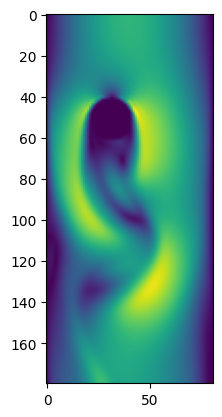

In [39]:
plt.imshow(np.linalg.norm(unflatten(data_cyl['u'], dataset_cyl.X.shape[0], dataset_cyl.X.shape[1], 5)[0], axis=0))